<h1 style='font-weight:bold; color:#003366; text-align:center;'>Tema 6: Visualización con Matplotlib y Seaborn</h1>

<h3 style='font-weight:bold; color:#003366; text-align:center;'>Programación Analítica II</h3>
<h4 style='font-weight:bold; color:#003366; text-align:center;'>Docente Camila Palomeque</h4>
<h4 style='font-weight:bold; color:#003366; text-align:center;'>S2 . 2026</h4>

## Objetivos

1. Elegir el gráfico que responde a la pregunta, en lugar de elegir el que sale más rápido.
2. Trabajar con la interfaz `fig, ax` de Matplotlib.
3. Leer y construir los cuatro gráficos más comúnes en finanzas: línea, barras, histograma y boxplot.
4. Usar Seaborn para comparaciones por categoría y mapas de calor.
5. Detectar las tres formas más comunes de mentir con un gráfico, empezando por el eje truncado.

**Un gráfico tiene que comunicar algo de valor.**

In [16]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def ruta_datos(nombre_archivo):
    """Busca el archivo en las ubicaciones habituales del curso, incluida Colab."""
    candidatas = [
        Path("../Datos") / nombre_archivo,
        Path("Datos") / nombre_archivo,
        Path("/content/Datos") / nombre_archivo,
        Path(nombre_archivo),
    ]
    for candidata in candidatas:
        if candidata.exists():
            return str(candidata)
    raise FileNotFoundError(f"No se encontró {nombre_archivo}.")


# Todo lo que el notebook exporte (PNG, HTML) va acá y no al lado del notebook.
CARPETA_SALIDAS = Path("salidas")
CARPETA_SALIDAS.mkdir(exist_ok=True)

# Paleta institucional UM: dos azules, un DORADO para destacar y un gris para el resto.
AZUL = "#11224D"
AZUL_CLARO = "#6699CC"
DORADO = "#D4AF37"
GRIS = "#BBBBBB"

# Configuración global: se aplica a todos los gráficos del notebook.
plt.rcParams["figure.figsize"] = (10, 4.5) # Tamaño de la figura en pulgadas (ancho, alto)
plt.rcParams["font.size"] = 11 # Tamaño letra
plt.rcParams["axes.spines.top"] = False # Ocultar el borde superior de los ejes
plt.rcParams["axes.spines.right"] = False # Ocultar el borde derecho de los ejes
plt.rcParams["axes.titlesize"] = 12 # Tamaño del título de los ejes

In [17]:
ventas = pd.read_csv(ruta_datos("ventas_ecommerce.csv"), parse_dates=["fecha"])
ventas["facturacion"] = ventas["unidades"] * ventas["precio_unitario"] * (1 - ventas["descuento"])

acciones = pd.read_csv(ruta_datos("acciones.csv"), parse_dates=["fecha"])

# Sacamos los duplicados y los ingresos faltantes acá, una vez, para no repetirlo en cada gráfico.
credito = (
    pd.read_csv(ruta_datos("credito_clientes.csv"))
    .drop_duplicates(subset=["id_cliente"])
    .dropna(subset=["ingreso_mensual"])
)

print(f"Ventas: {len(ventas):,} órdenes, de {ventas['fecha'].min():%b %Y} a {ventas['fecha'].max():%b %Y}")
print(f"Acciones: {acciones['ticker'].nunique()} tickers, {len(acciones):,} filas diarias")
print(f"Crédito: {len(credito):,} solicitudes con ingreso informado")

Ventas: 8,637 órdenes, de Jan 2024 a Jun 2026
Acciones: 5 tickers, 4,560 filas diarias
Crédito: 3,088 solicitudes con ingreso informado


<h2 style='font-weight:bold; color:#003366;'>1. Por qué visualizar</h2>

En 1973 el estadístico Frank Anscombe armó cuatro conjuntos de datos con **la misma media, la misma varianza y la misma correlación**. 

Si los resumís en una tabla, son indistinguibles.
La forma de darse cuenta que no son los mismos datos es visualizarlos.

In [18]:
anscombe = {
    "Conjunto 1": ([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5],
          [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "Conjunto 2": ([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5],
           [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "Conjunto 3": ([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5],
            [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "Conjunto 4": ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
           [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}

resumen_anscombe = pd.DataFrame(
    {
        nombre: {
            "Media de x": np.mean(x),
            "Media de y": np.mean(y),
            "Desvío de y": np.std(y, ddof=1),
            "Correlación": np.corrcoef(x, y)[0, 1],
        }
        for nombre, (x, y) in anscombe.items()
    }
).round(2)

display(resumen_anscombe)

,Conjunto 1,Conjunto 2,Conjunto 3,Conjunto 4
Media de x,9.00,9.00,9.00,9.00
Media de y,7.50,7.50,7.50,7.50
Desvío de y,2.03,2.03,2.03,2.03
Correlación,0.82,0.82,0.82,0.82


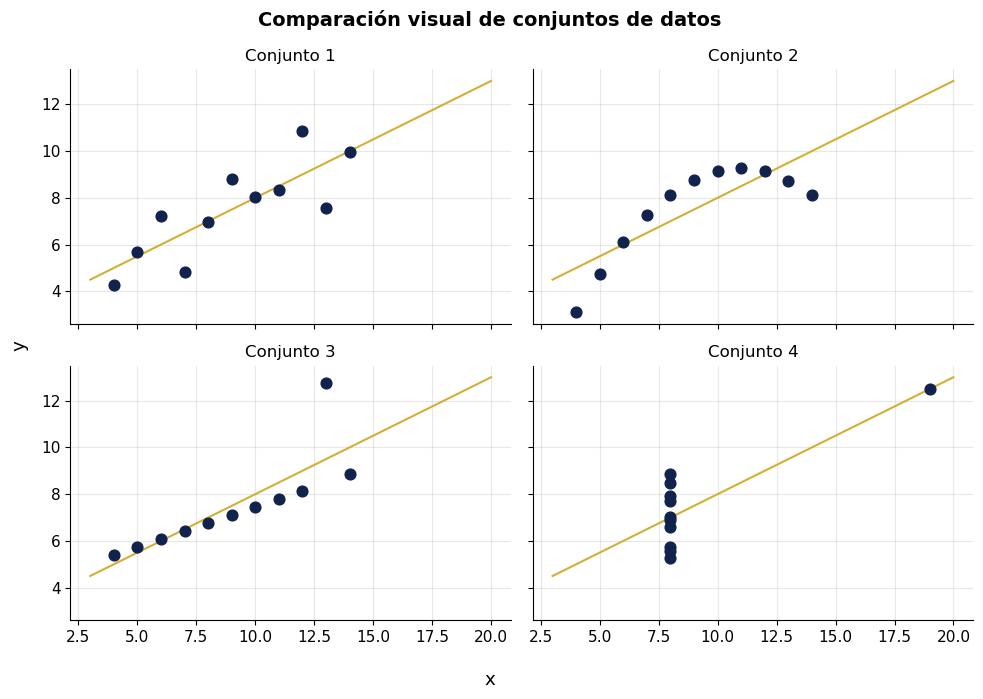

In [19]:
fig, ejes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
# sharex y sharey obligan a los cuatro paneles a usar la misma escala.
# Sin eso, la comparación visual sería tramposa.

for eje, (nombre, (x, y)) in zip(ejes.flat, anscombe.items()):
    eje.scatter(x, y, s=60, color=AZUL, zorder=3)
    eje.plot([3, 20], [3 + 0.5 * 3, 3 + 0.5 * 20], color=DORADO, linewidth=1.5)
    eje.set_title(f"{nombre}", loc="center")
    eje.grid(alpha=0.3)

fig.suptitle("Comparación visual de conjuntos de datos", fontsize=14, fontweight="bold")
fig.supxlabel("x")
fig.supylabel("y")
fig.tight_layout()
plt.show()

**La recta que ajustan los datos, idéntica porque los estadísticos son idénticos**. 

- Solo el conjunto 1 es una relación lineal genuina. 
- El Conjunto 2 es una curva.
- El Conjunto 3 es una recta perfecta con un dato mal cargado.
- El Conjunto 4 no tiene relación alguna: es un punto solo el que genera toda la correlación.

Graficar nos acerca a un resumen visual rápido de la distribución visual que de lo contrario no podríamos tener.

<h2 style='font-weight:bold; color:#003366;'>2. La interfaz que vamos a usar: <code>fig, ax</code></h2>

Matplotlib se puede usar de dos maneras y mezclarlas es la principal fuente de confusión.

- `plt.plot(...)` dibuja sobre "el gráfico actual", que es un objeto invisible que Matplotlib mantiene
  por atrás. Sirve para mirar algo rápido y seguir.
- `fig, ax = plt.subplots()` te devuelve dos objetos con nombre: la **figura** (la hoja) y el **ax**
  (el gráfico dentro de la hoja). A partir de ahí, todo se le pide al `ax`.

Usamos siempre la segunda, por un motivo práctico: cuando querés dos gráficos al lado, o cambiar la
escala de un eje, o poner una anotación, el estilo con `ax` es el único que escala. El otro te obliga a
reescribir todo.

**Anatomía de una gráfico** son cinco cosas básicas: 
1. Título
2. Etiqueta del eje x
3. Etiqueta del eje y
4. Leyenda (opcional pero recomendanble)
5. Grilla (opcional) 

In [20]:
facturacion_2026 = (
    ventas[ventas["fecha"].dt.year == 2026]
    .set_index("fecha")
    .resample("ME")["facturacion"]
    .sum()
    / 1_000_000
)

facturacion_2026

fecha
2026-01-31    4.182409
2026-02-28    4.912640
2026-03-31    5.972475
2026-04-30    4.823297
2026-05-31    4.113949
2026-06-30    4.240473
Freq: ME, Name: facturacion, dtype: float64

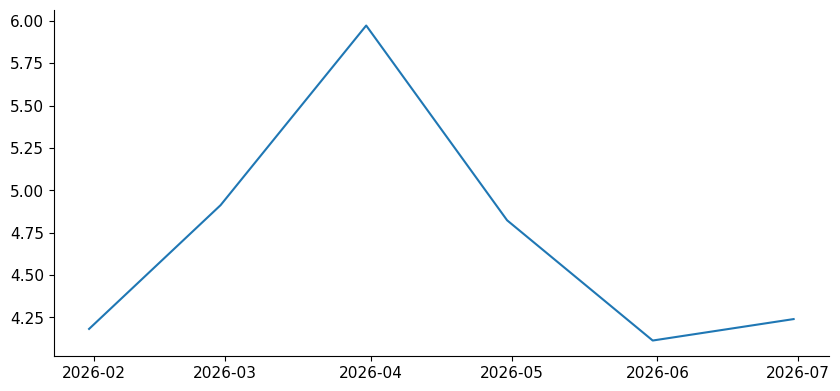

In [21]:
# Versión rápida: sirve para mirar, no para mostrar
plt.plot(facturacion_2026.index, facturacion_2026.values)
plt.show()

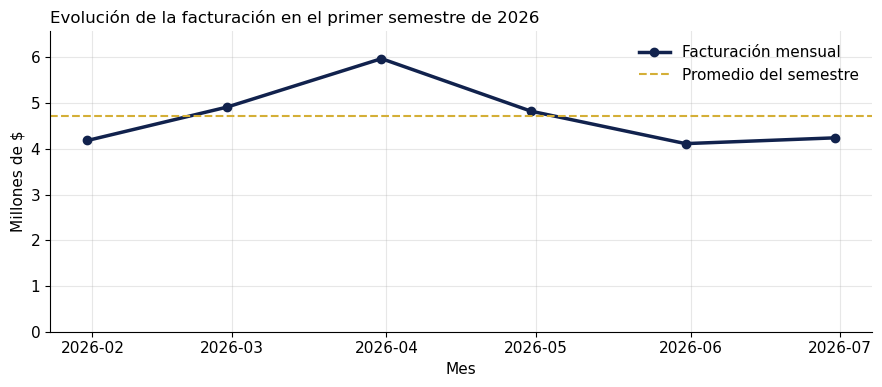

In [22]:
# Versión con fig, ax: los cinco elementos, uno por uno
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(facturacion_2026.index, facturacion_2026.values,
        color=AZUL, linewidth=2.5, marker="o", label="Facturación mensual")

ax.axhline(facturacion_2026.mean(), color=DORADO, linestyle="--",
           linewidth=1.5, label="Promedio del semestre")

ax.set_title("Evolución de la facturación en el primer semestre de 2026", loc="left")
ax.set_xlabel("Mes")
ax.set_ylabel("Millones de $")
ax.legend(frameon=False) #Apaga borde de la leyenda
ax.grid(alpha=0.3) # Pone grilla con transparencia
ax.set_ylim(0, facturacion_2026.values.max() * 1.1) # Ajusta el límite superior del eje y para que haya espacio por encima del máximo

fig.tight_layout()
plt.show()

<h2 style='font-weight:bold; color:#003366;'>3. Evolución en el tiempo: la línea</h2>

Los gráficos de línea responden a **cómo cambió esto a lo largo del tiempo**. 

La línea que une dos puntos comunica continuidad, así que solo se usa 
cuando el eje x tiene un orden natural: días, meses, años.

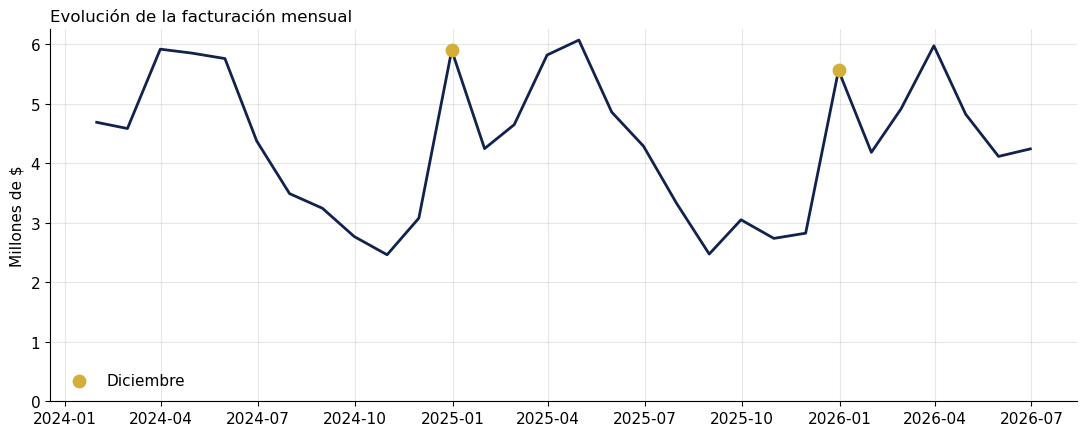

count    30.00
mean      4.34
std       1.18
min       2.46
25%       3.26
50%       4.33
75%       5.40
max       6.07
Name: facturacion, dtype: float64

In [23]:
facturacion_mensual = ventas.set_index("fecha").resample("ME")["facturacion"].sum() / 1_000_000

fig, ax = plt.subplots(figsize=(11, 4.5))

ax.plot(facturacion_mensual.index, facturacion_mensual.values, color=AZUL, linewidth=2)

# Marcamos los diciembres, porque son los que explican la forma de la serie.
diciembres = facturacion_mensual[facturacion_mensual.index.month == 12]
ax.scatter(diciembres.index, 
           diciembres.values, 
           color=DORADO, 
           s=80, #Tamaño de los marcadores
           zorder=3, #Para que los marcadores queden por encima de la línea
           label="Diciembre")

ax.set_title("Evolución de la facturación mensual", loc="left")
ax.set_xlabel("")
ax.set_ylabel("Millones de $")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
ax.set_ylim(0, None)

fig.tight_layout()
plt.show()

display(facturacion_mensual.describe().round(2))

No hay tendencia: la serie sube y baja entre 2,5 y 6 millones alrededor del mismo
nivel. Lo que hay es un patrón estacional muy marcado, con pico en diciembre y en marzo-abril, y piso en septiembre-octubre. 

**Cualquier comparación mes contra mes en este negocio es engañosa**: comparar
diciembre con octubre mide la estacionalidad, no la gestión. Se compara diciembre contra diciembre.

<h3 style='font-weight:bold; color:#0033BB;'>Ejemplo: el problema de comparar series con escalas distintas</h3>

Ahora el caso más frecuente en finanzas: cinco activos con precios muy diferentes en un mismo gráfico.
Uno cotiza a 40 y otro a 900, y el más caro se come todo el espacio vertical.

La solución es mostrarlos cómo **índices en base 100**: se divide cada serie por su primer valor y se multiplica por 100. 

Todas arrancan en 100 (momento base), y a partir de ahí el gráfico deja de mostrar precios y muestra **rendimientos
acumulados**. 

Un valor de 148 significa "acumuló 48% desde el inicio del período". 

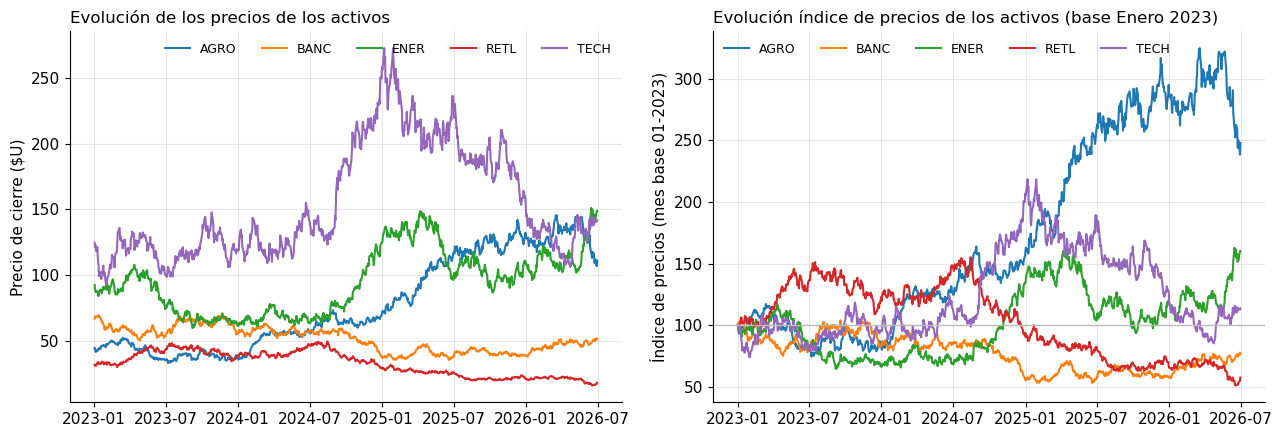

Rendimiento acumulado del período, en %:
ticker
AGRO    147.8
ENER     60.3
TECH     13.7
BANC    -23.3
RETL    -42.3


In [24]:
precios = acciones.pivot_table(index="fecha", columns="ticker", values="cierre")

# Base 100: cada columna dividida por su primer valor, por 100.
base_100 = precios.div(precios.iloc[0]).mul(100) # es otra forma de decir precios / precios.iloc[0] * 100

fig, (ax_precios, ax_base) = plt.subplots(1, 2, figsize=(13, 4.5))

for ticker in precios.columns:
    ax_precios.plot(precios.index, precios[ticker], linewidth=1.5, label=ticker)
    ax_base.plot(base_100.index, base_100[ticker], linewidth=1.5, label=ticker)

ax_precios.set_title("Evolución de los precios de los activos", loc="left")
ax_precios.set_ylabel("Precio de cierre ($U)")

ax_base.set_title("Evolución índice de precios de los activos (base Enero 2023)", loc="left")
ax_base.set_ylabel("Índice de precios (mes base 01-2023)")
ax_base.axhline(100, color=GRIS, linewidth=1)

for eje in (ax_precios, ax_base):
    eje.legend(frameon=False, ncols=5, fontsize=9)
    eje.grid(alpha=0.3)

fig.tight_layout()
plt.show()

rendimientos = (precios.iloc[-1] / precios.iloc[0] - 1).mul(100).round(1).sort_values(ascending=False)
print("Rendimiento acumulado del período, en %:")
print(rendimientos.to_string())

En el panel izquierdo, TECH domina la imagen porque cotiza cerca de 140 y RETL
cerca de 20. 

En el panel derecho, con las cinco series arrancando de 100, la conclusión se da vuelta: **TECH subió 14% y AGRO subió 148%**. El activo
que ocupaba más lugar en el gráfico era el que menos rindió.

**Regla:** si las series tienen escalas distintas y la pregunta es sobre rendimiento, puede tener sentido utilizar un índice de precios para hacer los resultados comparables.

<h2 style='font-weight:bold; color:#003366;'>4. Comparar categorías: barras</h2>

Las barras responden a **cuánto tiene cada categoría**. Tres reglas que hacen la diferencia:

1. **Ordenadas por valor**, salvo que el orden de las categorías tenga sentido propio (meses, tramos de
   edad, niveles educativos). Un gráfico de barras ordenado alfabéticamente desperdicia el gráfico.
2. **Horizontales cuando los nombres son largos.** `ax.barh()` evita las etiquetas rotadas 45 grados,
   que nadie lee con comodidad.
3. **Con la etiqueta del valor sobre la barra**, usando `ax.bar_label()`. Si el número importa, se
   escribe.

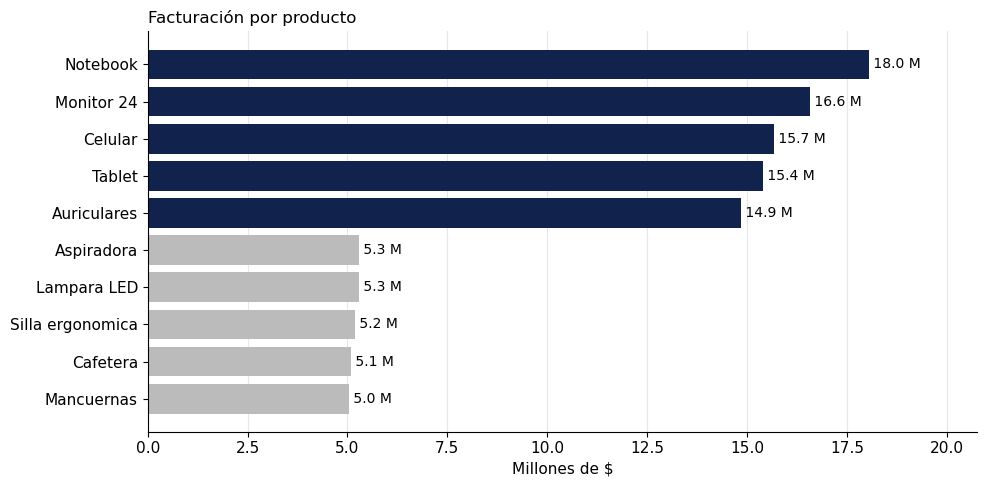

In [25]:
CATEGORIA_A_DESTACAR = "Electronica"

top_productos = (
    ventas.groupby(["categoria", "producto"])["facturacion"]
    .sum()
    .div(1_000_000)
    .nlargest(10)
    .sort_values()
    .reset_index()
)

# Gris para todo, color solo para lo que queremos que el lector mire.
colores = [AZUL if fila == CATEGORIA_A_DESTACAR else GRIS for fila in top_productos["categoria"]]

fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.barh(top_productos["producto"], top_productos["facturacion"], color=colores)

ax.bar_label(barras, fmt=" %.1f M", fontsize=10) #Agregar etiquetas a las barras con formato y tamaño de fuente

ax.set_title(f"Facturación por producto ", loc="left")
ax.set_xlabel("Millones de $")
ax.set_xlim(0, top_productos["facturacion"].max() * 1.15)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

Los cinco primeros puestos del ranking son de Electrónica, y los tres primeros
productos (Notebook, Monitor 24 y Celular) explican el **38,6% de toda la facturación** del comercio.

Una interrupción de stock en un solo proveedor pone en riesgo casi cuatro de cada
diez pesos facturados.

Pintar todo de gris y dejar un solo color dirige la mirada. Un
gráfico donde todas las barras tienen un color distinto no destaca nada.




<h3 style='font-weight:bold; color:#0033BB;'>Ejemplo: barras agrupadas y barras apiladas</h3>

Cuando hay dos dimensiones (categoría **y** canal, por ejemplo) hay dos formas de armar las barras, y no
son intercambiables.

In [26]:
tabla = (
    ventas.pivot_table(index="categoria", columns="canal", values="facturacion", aggfunc="sum")
    .div(1_000_000)
)
orden_categorias = tabla.sum(axis=1).sort_values(ascending=False).index
tabla = tabla.loc[orden_categorias]
tabla

canal,App movil,Marketplace,Telefono,Web
categoria,,,,
Electronica,26.661699,13.006699,6.199664,34.673825
Hogar,6.960334,3.639796,1.690290,8.567563
Deportes,4.644035,2.574557,1.060496,6.149495
Indumentaria,3.985634,2.320120,0.887059,5.065549
Libros,0.792868,0.394983,0.155776,0.815174


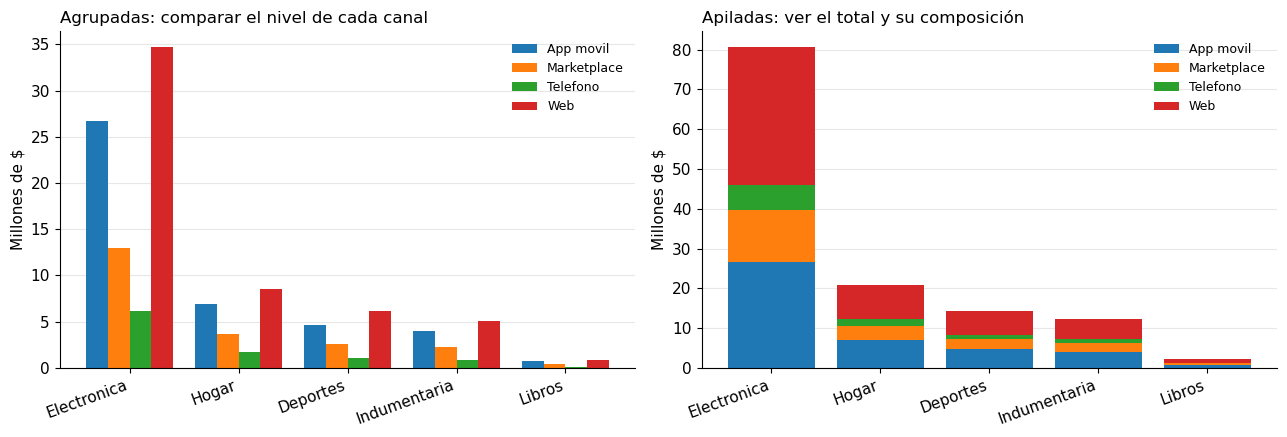

In [27]:
fig, (ax_agrupadas, ax_apiladas) = plt.subplots(1, 2, figsize=(13, 4.5))

posiciones = np.arange(len(tabla))
ancho = 0.8 / len(tabla.columns)

for numero, canal in enumerate(tabla.columns):
    ax_agrupadas.bar(posiciones + numero * ancho, tabla[canal], width=ancho, label=canal)

# Agrupadas: cada canal tiene su propia barra dentro de cada categoría.
ax_agrupadas.set_xticks(posiciones + ancho * 1.5)
ax_agrupadas.set_xticklabels(tabla.index, rotation=20, ha="right")
ax_agrupadas.set_title("Agrupadas: comparar el nivel de cada canal", loc="left")
ax_agrupadas.set_ylabel("Millones de $")

# Apiladas: cada canal arranca donde termina el anterior y hay una sola barra por categoría.
acumulado = np.zeros(len(tabla))
for canal in tabla.columns:
    ax_apiladas.bar(tabla.index, tabla[canal], bottom=acumulado, label=canal)
    acumulado = acumulado + tabla[canal].values

ax_apiladas.set_xticks(range(len(tabla)))
ax_apiladas.set_xticklabels(tabla.index, rotation=20, ha="right")
ax_apiladas.set_title("Apiladas: ver el total y su composición", loc="left")
ax_apiladas.set_ylabel("Millones de $")

for eje in (ax_agrupadas, ax_apiladas):
    eje.legend(frameon=False, fontsize=9)
    eje.grid(axis="y", alpha=0.3)
    eje.set_axisbelow(True)

fig.tight_layout()
plt.show()

**Cuándo usar cada una.** En las agrupadas todas las barras arrancan de cero, así
que se pueden comparar con precisión: Web es el canal más grande en Electrónica y App móvil la sigue de
cerca. 

En las apiladas se lee el total de cada categoría de un vistazo y se ve que Electrónica factura
casi cuatro veces más que Hogar, pero solo el segmento de abajo se puede medir bien. Los de arriba
"flotan" y el ojo no compara bien longitudes que no arrancan en el mismo lugar.

**Criterio:** agrupadas para comparar niveles, apiladas para mostrar composición. Si te interesan las
dos cosas, van dos gráficos.

<h2 style='font-weight:bold; color:#003366;'>5. Distribuciones: histograma y la asimetría</h2>

El histograma responde a **cómo se reparten los valores**. Parte el rango en intervalos (*bins*) y
cuenta cuántas observaciones caen en cada uno.

Vamos a visualizar facturación por compra, que es una variable con una propiedad muy común en
variables monetarias la **asimétrica a la derecha**: hay muchas órdenes chicas y unas pocas
enormes.

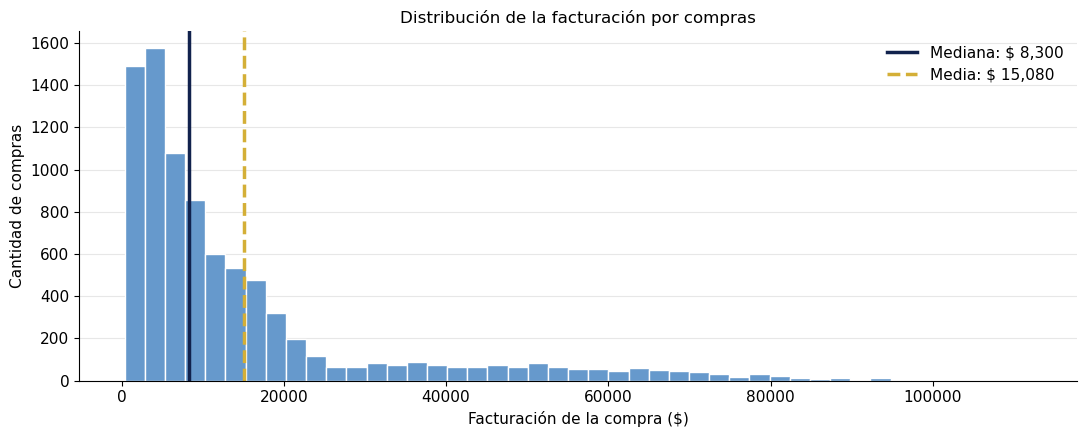

Media: $15,080
Mediana: $8,300
El 10% de compras más grandes explica el 40.7% de la facturación


In [ ]:
CANTIDAD_BINS = 45

facturacion_compra = ventas["facturacion"]
media = facturacion_compra.mean()
mediana = facturacion_compra.median()

fig, ax = plt.subplots(figsize=(11, 4.5))

# Gráfico principal (histograma)
ax.hist(facturacion_compra, bins=CANTIDAD_BINS, color=AZUL_CLARO, edgecolor="white")

# Líneas con información estadística para complementar el gráfico
ax.axvline(mediana, color=AZUL, linewidth=2.5, label=f"Mediana: $ {mediana:,.0f}")
ax.axvline(media, color=DORADO, linewidth=2.5, linestyle="--", label=f"Media: $ {media:,.0f}")

ax.set_title("Distribución de la facturación por compras", loc="center")
ax.set_xlabel("Facturación de la compra ($)")
ax.set_ylabel("Cantidad de compras")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

print(f"Media: ${media:,.0f}")
print(f"Mediana: ${mediana:,.0f}")
print(f"El 10% de compras más grandes explica el "
      f"{facturacion_compra.nlargest(int(len(ventas) * 0.1)).sum() / facturacion_compra.sum():.1%} "
      f"de la facturación")

La distribución tiene una única moda pegada a la
izquierda y una cola larga hacia la derecha. La media ($U 15.080) está muy a la derecha de la mediana
($U 8.300), porque unas pocas órdenes de Electrónica de más de $U 80.000 la empujan.

Consecuencias:

- **El "ticket promedio" sobreestima lo que gasta un cliente típico.** La mitad de las órdenes está por
  debajo de $U 8.300, no de $U 15.080. Si dimensionás el stock o la logística con el promedio, te
  equivocás para la mayoría de los casos.
- **El 10% de órdenes más grandes explica el 41% de la facturación.** Ese es el número que importa para
  decidir dónde poner el esfuerzo comercial.

Cuando una distribución es asimétrica, la mediana describe al caso típico y la media describe al total
dividido. Son dos preguntas distintas y conviene reportar las dos.

> **Cambiá `CANTIDAD_BINS` a 5, después a 15, después a 200** y volvé a correr la celda
> cada vez.
>
> ¿Con cuántos bins aparece la cola de la derecha? ¿Con cuántos desaparece? Un voluntario dice qué valor
> elegiría para poner este gráfico en un informe, y por qué. La cantidad de bins **no es un detalle
> estético: cambia la historia que cuenta el gráfico.**

<h2 style='font-weight:bold; color:#003366;'>6. Comparar distribuciones: el boxplot</h2>

El boxplot resume una distribución en cinco números, y sirve para comparar varios grupos en un solo
gráfico. Cómo se lee una caja, de adentro hacia afuera:

| Elemento | Qué es |
|---|---|
| La línea del medio | La **mediana**: la mitad de los casos está por debajo |
| Los bordes de la caja | Primer y tercer **cuartil**: dentro de la caja está el 50% central |
| El largo de la caja | El **rango intercuartílico**, la medida de dispersión del grupo |
| Los bigotes | Hasta 1,5 rangos intercuartílicos desde la caja |
| Los puntos sueltos | Casos **atípicos** según ese criterio, que no significa "errores" |

Un detalle que mejora la visualización **ordenar los grupos por mediana**.

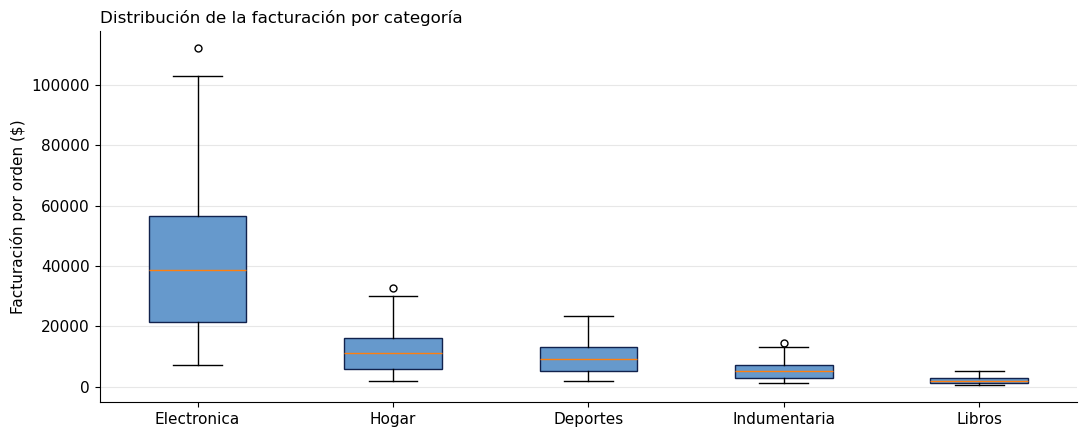

,50%,25%,75%,max
categoria,,,,
Deportes,9083.0,5100.0,13234.0,23285.0
Electronica,38702.0,21443.0,56545.0,112171.0
Hogar,11209.0,5956.0,16078.0,32761.0
Indumentaria,5049.0,2765.0,7228.0,14540.0
Libros,1964.0,1078.0,2767.0,5024.0


In [29]:
# Ordenar las categorías por la mediana de facturación, de mayor a menor, para que el gráfico sea más fácil de leer.
orden_por_mediana = (
    ventas.groupby("categoria")["facturacion"].median().sort_values(ascending=False).index)

datos_por_categoria = []
for categoria in orden_por_mediana:
    datos_por_categoria.append(ventas.loc[ventas["categoria"] == categoria, "facturacion"])

fig, ax = plt.subplots(figsize=(11, 4.5))

caja = ax.boxplot(datos_por_categoria, 
                  patch_artist=True, # Rellenar los boxplots con color
                  flierprops={"marker": "o", "markersize": 5})

for cuerpo in caja["boxes"]:
    cuerpo.set_facecolor(AZUL_CLARO)
    cuerpo.set_edgecolor(AZUL)

# Las etiquetas se ponen aparte: el nombre del parámetro de boxplot cambió entre versiones.
ax.set_xticks(range(1, len(orden_por_mediana) + 1))
ax.set_xticklabels(orden_por_mediana)

ax.set_title("Distribución de la facturación por categoría", loc="left")
ax.set_ylabel("Facturación por orden ($)")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

display(ventas.groupby("categoria")["facturacion"].describe()[["50%", "25%", "75%", "max"]].round(0))

El orden por mediana deja el gráfico legible de un vistazo: Electrónica
(mediana $U 38.700), Hogar ($U 11.200), Deportes ($U 9.100), Indumentaria ($U 5.000) y Libros
($U 1.960).

**El largo de las cajas**: la caja de Electrónica es
enorme y la de Libros es casi una línea. En Libros el monto de la compra es predecible, en Electrónica una compra
puede ser de $U 15.000 o de $U 80.000.

**Cuándo el boxplot le gana a las barras de promedios:** cuando la pregunta es sobre la dispersión y no
sobre el total. "¿Cuánto factura cada categoría?" se contesta con barras. "¿Qué tan parejo es el ticket
dentro de cada categoría?" solo se contesta con un boxplot, porque un promedio esconde exactamente eso.

<h2 style='font-weight:bold; color:#003366;'>7. Relación entre dos variables: la dispersión</h2>

El gráfico de dispersión responde a **cómo se relacionan estas dos variables**. Es el gráfico donde
aparecen las correlaciones, los grupos y los datos mal cargados.

Su problema propio es el **sobregraficado**: con 3.000 puntos, la zona densa se convierte en una mancha
sólida y deja de informar. Tres soluciones, que se combinan:

1. **Transparencia** con `alpha`: donde hay muchos puntos superpuestos, el color se satura.
2. **Puntos más chicos** con `s`.
3. **Escala logarítmica**, cuando las dos variables son montos.

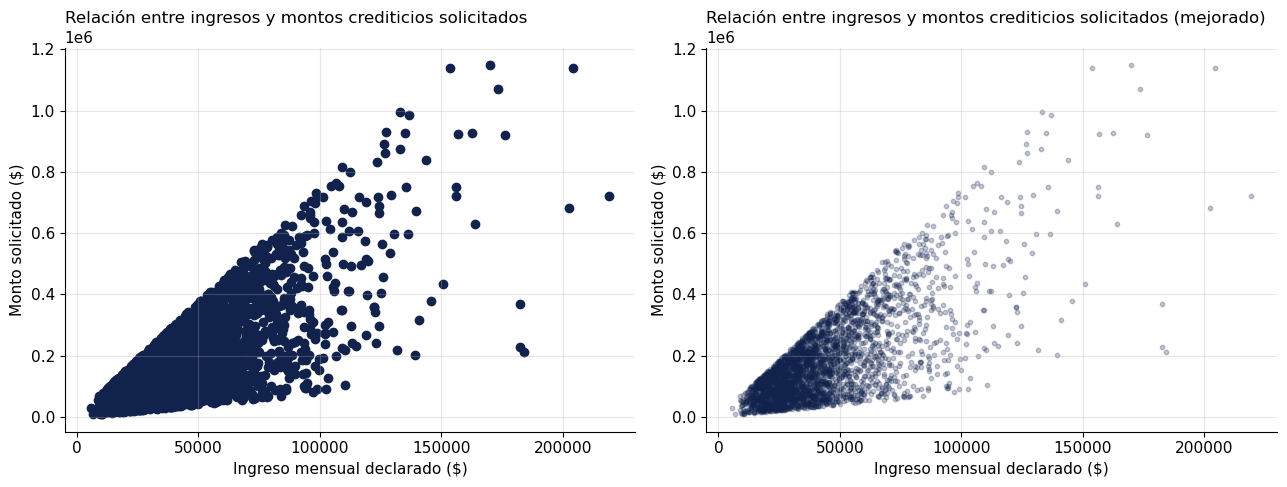

Correlación entre ingreso y monto solicitado: 0.74


In [30]:
fig, (ax_crudo, ax_mejorado) = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico puro
ax_crudo.scatter(credito["ingreso_mensual"], credito["monto_solicitado"], color=AZUL)
ax_crudo.set_title("Relación entre ingresos y montos crediticios solicitados", loc="left")

# Gráfico mejorando la legibilidad: puntos chicos, transparencia y escala logarítmica (opcional).
ax_mejorado.scatter(credito["ingreso_mensual"], credito["monto_solicitado"],
                    s=10, alpha=0.25, color=AZUL)

#ax_mejorado.set_xscale("log")
#ax_mejorado.set_yscale("log")
ax_mejorado.set_title("Relación entre ingresos y montos crediticios solicitados (mejorado)", loc="left")

for eje in (ax_crudo, ax_mejorado):
    eje.set_xlabel("Ingreso mensual declarado ($)")
    eje.set_ylabel("Monto solicitado ($)")
    eje.grid(alpha=0.3)

fig.tight_layout()
plt.show()

# Estadístico de resumen: correlación entre ingreso y monto solicitado.
correlacion = credito["ingreso_mensual"].corr(credito["monto_solicitado"])
print(f"Correlación entre ingreso y monto solicitado: {correlacion:.2f}")

La correlación positiva es alta: quien gana más pide más. 

Pero eso solo se ve en el panel derecho. En el izquierdo, la nube tapada por sí misma sugiere que hay relación y no deja
ver de qué forma. 

Con la escala log-log la nube se vuelve una banda de pendiente clara y aparece algo
más: el borde inferior derecho está vacío, es decir **casi nadie con ingreso alto pide un monto chico**.

<h2 style='font-weight:bold; color:#003366;'>8. Varios paneles: <code>subplots</code></h2>

`plt.subplots(filas, columnas)` devuelve la figura y un arreglo de ejes. Es la forma de armar un tablero
en una sola imagen, que es lo que se pega en un informe.

Dos parámetros que importan:

- `sharey=True` fuerza la misma escala vertical en todos los paneles. **Se usa cuando los paneles miden
  lo mismo** (como en el cuarteto de Anscombe). Si miden cosas distintas, compartir el eje deforma.
- `fig.tight_layout()` acomoda los espacios para que los títulos no se pisen. Va siempre, al final.

In [31]:
c

NameError: name 'c' is not defined

C:\Users\nicog\AppData\Local\Temp\ipykernel_20932\2200739197.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_evolucion.set_xticklabels(facturacion_mensual.index.strftime("%Y-%m"), rotation=20, ha="right")


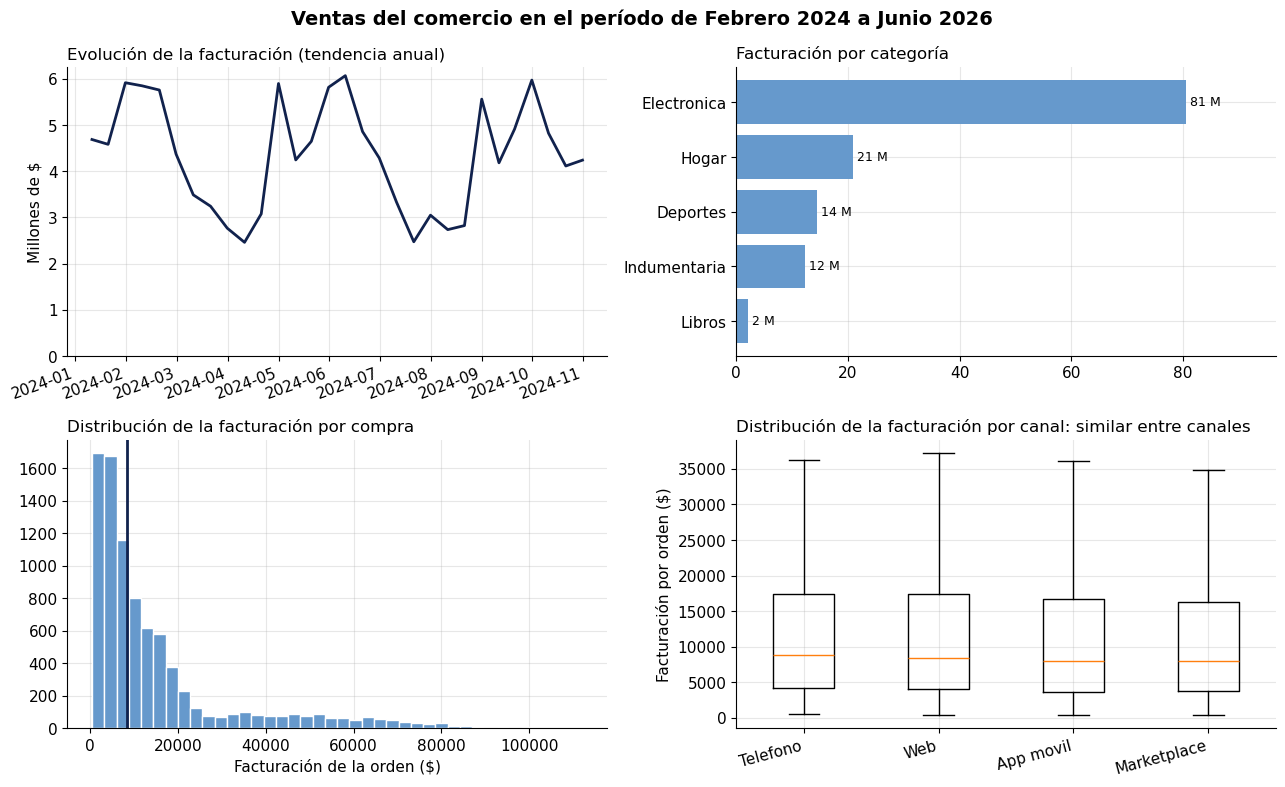

In [33]:
fig, ejes = plt.subplots(2, 2, figsize=(13, 8))
(ax_evolucion, ax_ranking), (ax_distribucion, ax_dispersion_canal) = ejes

# Panel 1: evolución
ax_evolucion.plot(facturacion_mensual.index, facturacion_mensual.values, color=AZUL, linewidth=2)
ax_evolucion.set_title("Evolución de la facturación (tendencia anual)", loc="left")
ax_evolucion.set_ylabel("Millones de $")
ax_evolucion.set_ylim(0, None)
ax_evolucion.set_xticklabels(facturacion_mensual.index.strftime("%Y-%m"), rotation=20, ha="right")

# Panel 2: ranking
por_categoria = ventas.groupby("categoria")["facturacion"].sum().div(1_000_000).sort_values()
barras = ax_ranking.barh(por_categoria.index, por_categoria.values, color=AZUL_CLARO)
ax_ranking.bar_label(barras, fmt=" %.0f M", fontsize=9)
ax_ranking.set_title("Facturación por categoría", loc="left")
ax_ranking.set_xlim(0, por_categoria.max() * 1.2)

# Panel 3: distribución
ax_distribucion.hist(facturacion_compra, bins=40, color=AZUL_CLARO, edgecolor="white")
ax_distribucion.axvline(mediana, color=AZUL, linewidth=2)
ax_distribucion.set_title("Distribución de la facturación por compra", loc="left")
ax_distribucion.set_xlabel("Facturación de la orden ($)")

# Panel 4: dispersión por canal
orden_canal = ventas.groupby("canal")["facturacion"].median().sort_values(ascending=False).index
ax_dispersion_canal.boxplot([ventas.loc[ventas["canal"] == c, "facturacion"] for c in orden_canal],
                            showfliers=False)
ax_dispersion_canal.set_xticks(range(1, len(orden_canal) + 1))
ax_dispersion_canal.set_xticklabels(orden_canal, rotation=15, ha="right")
ax_dispersion_canal.set_title("Distribución de la facturación por canal: similar entre canales", loc="left")
ax_dispersion_canal.set_ylabel("Facturación por orden ($)")

for eje in ejes.flat:
    eje.grid(alpha=0.3)
    eje.set_axisbelow(True)

fig.suptitle("Ventas del comercio en el período de Febrero 2024 a Junio 2026", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

Los cuatro paneles juntos cuentan una historia completa: el negocio no crece, es
estacional, depende de una categoría (62% en Electrónica), tiene tickets muy desparejos, y el canal de
venta **no** explica esa disparidad. Ese último panel es el más valioso del tablero, porque descarta una
hipótesis: no hay que buscar la diferencia de ticket en el canal.


<h2 style='font-weight:bold; color:#003366;'>9. Seaborn</h2>

Seaborn está construido sobre Matplotlib. No lo reemplaza: le agrega dos cosas.

1. **Trabaja directo con el DataFrame.** En lugar de armar listas por grupo, le pasás
   `data=ventas, x="facturacion", y="categoria"` y agrupa solo.
2. **Elige valores por omisión razonables**: paletas, orden, tamaños de fuente.

Lo usamos para tres cosas: `barplot`, `boxplot` y, sobre todo, `heatmap`, que en Matplotlib puro es
tedioso de armar.

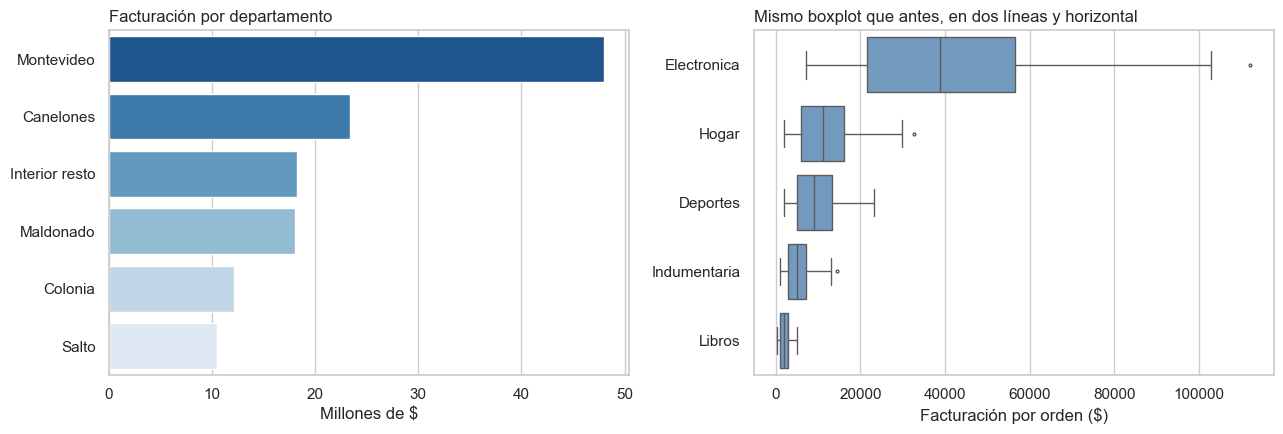

In [34]:
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.0)

por_region = (
    ventas.groupby("region", as_index=False)["facturacion"].sum()
    .assign(millones=lambda datos: datos["facturacion"] / 1_000_000)
    .sort_values("millones", ascending=False)
)

fig, (ax_barras, ax_cajas) = plt.subplots(1, 2, figsize=(13, 4.5))

# Gráfico de barras
sns.barplot(data=por_region, x="millones", y="region", hue="region",
            palette="Blues_r", legend=False, ax=ax_barras)
ax_barras.set_title("Facturación por departamento", loc="left")
ax_barras.set_xlabel("Millones de $")
ax_barras.set_ylabel("")

# Gráfico de caja
sns.boxplot(data=ventas, x="facturacion", y="categoria", order=orden_por_mediana,
            color=AZUL_CLARO, fliersize=2, ax=ax_cajas)
ax_cajas.set_title("Mismo boxplot que antes, en dos líneas y horizontal", loc="left")
ax_cajas.set_xlabel("Facturación por orden ($)")
ax_cajas.set_ylabel("")

fig.tight_layout()
plt.show()

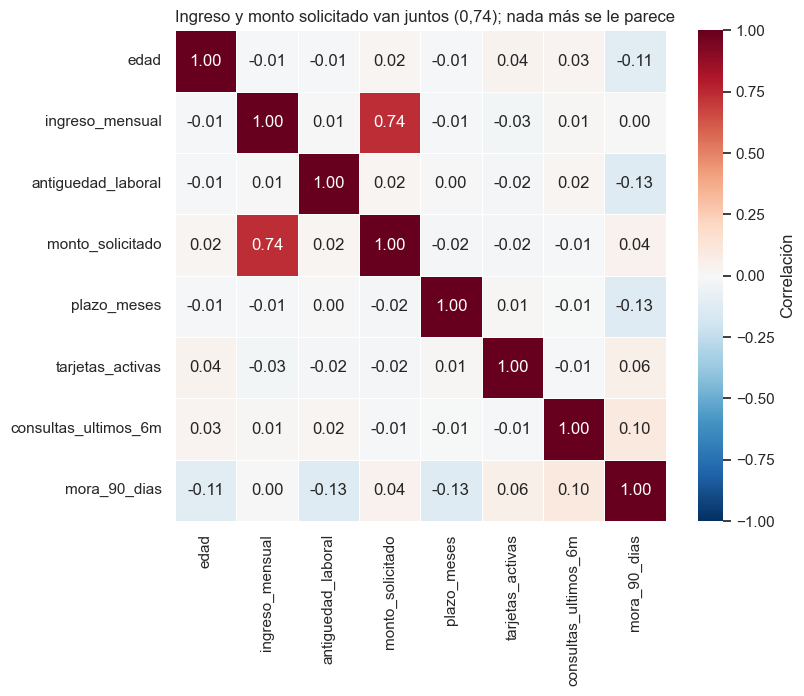

In [35]:
variables_credito = ["edad", "ingreso_mensual", "antiguedad_laboral", "monto_solicitado",
                     "plazo_meses", "tarjetas_activas", "consultas_ultimos_6m", "mora_90_dias"]

matriz_correlacion = credito[variables_credito].corr()

fig, ax = plt.subplots(figsize=(8.5, 7))

sns.heatmap(matriz_correlacion, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, square=True,
            cbar_kws={"label": "Correlación"}, ax=ax)

ax.set_title("Ingreso y monto solicitado van juntos (0,74); nada más se le parece", loc="left")
fig.tight_layout()
plt.show()

El mapa de calor se lee buscando el rojo y el azul fuerte. Solo hay un par
realmente correlacionado: ingreso y monto solicitado (0,74). Todo lo demás está entre -0,13 y 0,10, es
decir, prácticamente sin relación lineal. **La mora casi no correlaciona con nada**, ni con el ingreso (0,00) ni
con el monto (0,04) entonces las variables que vienen en la tabla no alcanzan para explicar linealmente la
mora, y hay que **construir** variables nuevas.

Dos detalles obligatorios del mapa de correlación: `center=0` y una paleta divergente. Con una paleta
secuencial, una correlación de -0,8 y una de 0 se ven casi igual.




<h2 style='font-weight:bold; color:#003366;'>10. Los errores que hay que saber detectar</h2>

Las tres formas más frecuentes de que un gráfico diga algo que
los datos no dicen, y las vas a encontrar en informes reales.

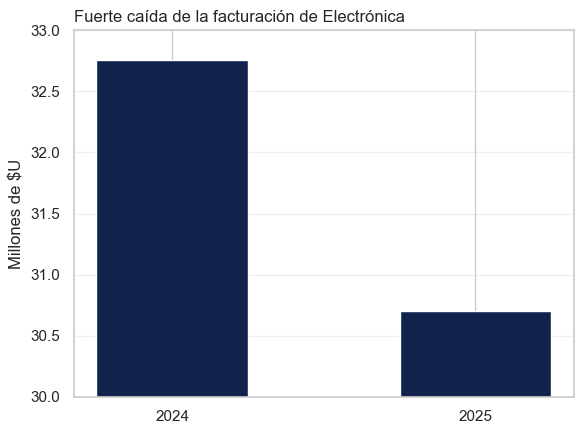

In [36]:
electronica_anual = (
    ventas[ventas["categoria"] == "Electronica"]
    .assign(anio=lambda datos: datos["fecha"].dt.year)
    .query("anio in [2024, 2025]")
    .groupby("anio")["facturacion"].sum()
    .div(1_000_000)
)

fig, ax = plt.subplots(figsize=(6, 4.5))

ax.bar(electronica_anual.index.astype(str), electronica_anual.values, color=AZUL, width=0.5)
ax.set_ylim(30, 33)  # <-- acá está la trampa
ax.set_title("Fuerte caída de la facturación de Electrónica", loc="left")
ax.set_ylabel("Millones de $U")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

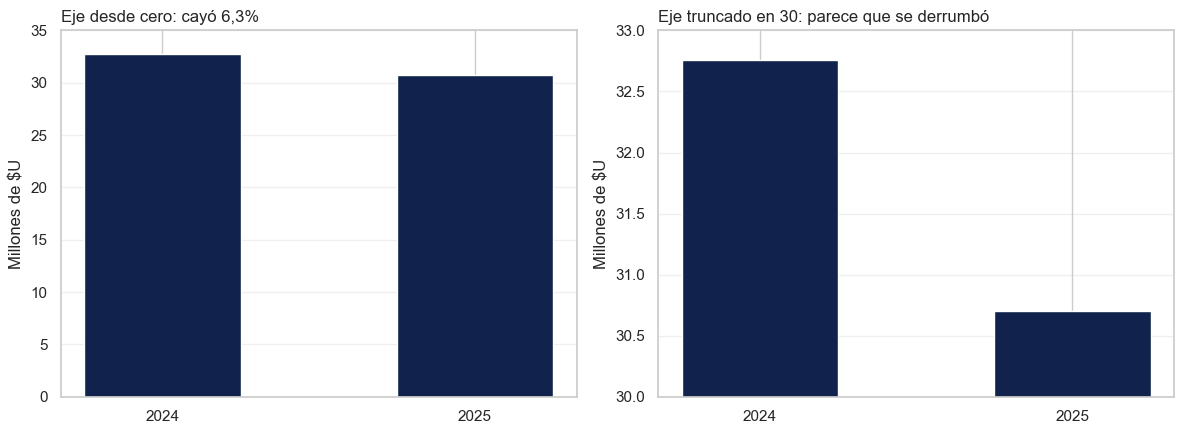

Variación real 2025 contra 2024: -6.3%


In [37]:
fig, (ax_cero, ax_truncado) = plt.subplots(1, 2, figsize=(12, 4.5))

for eje in (ax_cero, ax_truncado):
    eje.bar(electronica_anual.index.astype(str), electronica_anual.values, color=AZUL, width=0.5)
    eje.set_ylabel("Millones de $U")
    eje.grid(axis="y", alpha=0.3)
    eje.set_axisbelow(True)

ax_cero.set_ylim(0, 35)
ax_cero.set_title("Eje desde cero: cayó 6,3%", loc="left")

ax_truncado.set_ylim(30, 33)
ax_truncado.set_title("Eje truncado en 30: parece que se derrumbó", loc="left")

fig.tight_layout()
plt.show()

variacion = electronica_anual.loc[2025] / electronica_anual.loc[2024] - 1
print(f"Variación real 2025 contra 2024: {variacion:.1%}")

Son los mismos dos números en los dos paneles. La caída real es del **6,3%**,
que para un negocio es una señal a mirar pero no una catástrofe. Con el eje arrancando en 30, la barra
de 2025 mide menos de la mitad que la de 2024 y el ojo lee "cayó 60%".

Por qué pasa: en un gráfico de barras, **el área comunica la magnitud**. Si le cortás la base a la
barra, el área deja de ser proporcional al valor y el gráfico miente sin decir una sola cifra falsa.

En una línea, en cambio, el eje truncado es aceptable y a veces necesario, porque lo que comunica la
línea es la pendiente y no el área.

Los otros dos errores frecuentes:

- **La paleta que inventa un orden.** Usar una paleta secuencial (de claro a oscuro) para categorías sin
  orden (regiones, canales, rubros) hace creer que hay una jerarquía. Para categorías sin orden va una
  paleta con colores distinguibles, el degradé se reserva para variables ordenadas o numéricas.

- **La torta con ocho porciones.** El ojo compara longitudes bien y ángulos mal. Con más de tres
  porciones ya no se puede ordenar de memoria qué es más grande, y encima no se pueden poner etiquetas
  legibles. Casi nunca conviene: las mismas proporciones en barras horizontales ordenadas se leen mejor
  y ocupan menos espacio. 

<h2 style='font-weight:bold; color:#003366;'>11. Una función de estilo reutilizable, y cómo guardar</h2>

Hasta acá repetimos las mismas cinco líneas en cada gráfico: título a la izquierda, grilla suave, sacar
los bordes, formatear los miles. Eso se encapsula en una función.

Y para guardar, `fig.savefig()` con dos argumentos que hacen la diferencia:

- `dpi=200`: resolución suficiente para un informe impreso. El valor por omisión (100) se ve borroso.
- `bbox_inches="tight"`: recorta el blanco de más y evita que se corten las etiquetas.

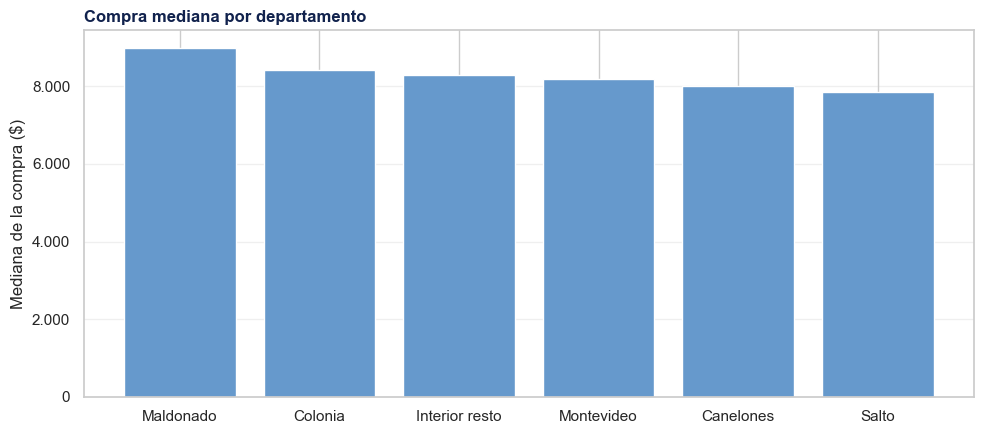

Figura guardada en: salidas\ticket_mediano_por_region.png
region
Maldonado         8989.0
Colonia           8418.0
Interior resto    8302.0
Montevideo        8195.0
Canelones         7996.0
Salto             7864.0


In [38]:
def aplicar_estilo_clase(ax, titulo, etiqueta_y=""):
    """Aplica el formato del curso a un eje: título a la izquierda, grilla suave y miles con punto."""
    ax.set_title(titulo, loc="left", fontsize=12, color=AZUL, fontweight="bold")
    ax.set_ylabel(etiqueta_y)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.yaxis.set_major_formatter(lambda valor, posicion: f"{valor:,.0f}".replace(",", "."))
    return ax


ticket_por_region = ventas.groupby("region")["facturacion"].median().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(ticket_por_region.index, ticket_por_region.values, color=AZUL_CLARO)
aplicar_estilo_clase(ax, "Compra mediana por departamento", "Mediana de la compra ($)")
fig.tight_layout()

CARPETA_SALIDAS.mkdir(exist_ok=True)
ruta_png = CARPETA_SALIDAS / "ticket_mediano_por_region.png"
fig.savefig(ruta_png, dpi=200, bbox_inches="tight")
plt.show()

print(f"Figura guardada en: {ruta_png}")
print(ticket_por_region.round(0).to_string())

<h2 style='font-weight:bold; color:#003366;'>Qué gráfico usar según la pregunta</h2>

| La pregunta que te hacen | El gráfico que la contesta |
|---|---|
| ¿Cómo evolucionó esto en el tiempo? | Línea |
| ¿Qué activo o sucursal rindió más, si arrancan de niveles distintos? | Línea en base 100 |
| ¿Cuánto tiene cada categoría? | Barras horizontales ordenadas, con etiquetas |
| ¿Cómo se compone el total de cada categoría? | Barras apiladas |
| ¿Cómo se comparan dos series por categoría? | Barras agrupadas |
| ¿Cómo se reparten los valores de una variable? | Histograma |
| ¿Qué tan dispersa es la variable dentro de cada grupo? | Boxplot ordenado por mediana |
| ¿Estas dos variables van juntas? | Dispersión, con `alpha` |
| ¿Qué variables se mueven juntas, entre muchas? | Mapa de calor de correlación |
| ¿Cuánto es un solo número clave? | Ninguno: escribí el número |

Un gráfico de barras con dos barras casi siempre se reemplaza mejor por una
oración: "la facturación de Electrónica cayó 6,3% en 2025".

<h2 style='font-weight:bold; color:#003366; text-align:center;'>Ejercicios</h2>

La cantidad de asteriscos indica la dificultad. Una estrella es aplicar lo que acabamos de ver
cambiando el dato; dos es combinar dos cosas de la clase.

**En todos los ejercicios se pide lo mismo además del código: un título que comunique el hallazgo y una
frase de interpretación.** Un gráfico sin conclusión no está terminado.

<h3 style='font-weight:bold; color:#BB3300; text-align:left;'>EJERCICIO 1 *</h3>

Graficá la evolución mensual de la facturación del canal **App movil** con una línea.

Requisitos: los cinco elementos de la anatomía (título, etiquetas de los dos ejes, leyenda o
referencia, grilla), el eje y arrancando en cero, y un título que diga qué encontraste.

<details>
<summary><b>Ver solución</b></summary>

```python
app_movil = (
    ventas[ventas["canal"] == "App movil"]
    .set_index("fecha")
    .resample("ME")["facturacion"]
    .sum()
    .div(1_000_000)
)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(app_movil.index, app_movil.values, color=AZUL, linewidth=2, label="App móvil")
ax.set_title("La app repite el patrón estacional del total: pico en diciembre, piso en octubre",
             loc="left")
ax.set_xlabel("")
ax.set_ylabel("Millones de $U")
ax.set_ylim(0, None)
ax.legend(frameon=False)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

# Interpretación: el canal no tiene una dinámica propia, sigue la del negocio.
# Un cambio en la app no se puede evaluar mirando esta serie sin descontar la estacionalidad.
```

</details>

In [ ]:
# Tu código acá


<h3 style='font-weight:bold; color:#BB3300; text-align:left;'>EJERCICIO 2 *</h3>

Hacé un gráfico de **barras horizontales ordenadas** con la facturación total por región, en
millones de pesos, con la etiqueta del valor sobre cada barra.

Pintá de gris todas las regiones menos Montevideo, y escribí en una línea qué implica el resultado para
una decisión de expansión.

<details>
<summary><b>Ver solución</b></summary>

```python
por_region = (
    ventas.groupby("region")["facturacion"].sum().div(1_000_000).sort_values()
)
colores = [AZUL if region == "Montevideo" else GRIS for region in por_region.index]

fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.barh(por_region.index, por_region.values, color=colores)
ax.bar_label(barras, fmt=" %.1f M", fontsize=10)
ax.set_title("Montevideo explica el 37% de la facturación; el resto está muy repartido", loc="left")
ax.set_xlabel("Millones de $U")
ax.set_xlim(0, por_region.max() * 1.15)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

# Interpretación: no hay una segunda plaza grande para atacar. Canelones es la mitad de Montevideo
# y las otras cuatro regiones son parecidas entre sí, así que una expansión regional tiene que
# apuntar a varias a la vez o no mueve el total.
```

</details>

In [ ]:
# Tu código acá


<h3 style='font-weight:bold; color:#BB3300; text-align:left;'>EJERCICIO 3 **</h3>

Hacé un **boxplot de la facturación por orden según el canal**, ordenado por mediana de mayor a
menor, y sin mostrar los puntos atípicos.

Después contestá: ¿qué canal tiene el ticket más disperso? ¿La respuesta cambia la conclusión del
tablero de la sección 8?

<details>
<summary style="cursor:pointer; color:#0033BB;"><b>Pista</b> (abrila solo después de intentarlo)</summary>

Para ordenar, calculá primero `ventas.groupby("canal")["facturacion"].median().sort_values(ascending=False).index`
y usá ese orden para armar la lista de series. En `ax.boxplot()`, `showfliers=False` esconde los
atípicos. Para medir la dispersión de cada grupo, mirá el rango intercuartílico: `75%` menos `25%` de
`describe()`.

</details>

<details>
<summary><b>Ver solución</b></summary>

```python
orden_canal = (
    ventas.groupby("canal")["facturacion"].median().sort_values(ascending=False).index
)
datos_por_canal = [ventas.loc[ventas["canal"] == canal, "facturacion"] for canal in orden_canal]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot(datos_por_canal, showfliers=False, patch_artist=True,
           medianprops={"color": DORADO, "linewidth": 2},
           boxprops={"facecolor": AZUL_CLARO, "edgecolor": AZUL})
ax.set_xticks(range(1, len(orden_canal) + 1))
ax.set_xticklabels(orden_canal)
ax.set_title("Los cuatro canales tienen la misma distribución de ticket", loc="left")
ax.set_ylabel("Facturación por orden ($U)")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

resumen = ventas.groupby("canal")["facturacion"].describe()[["25%", "50%", "75%"]]
print((resumen.assign(rango_intercuartilico=resumen["75%"] - resumen["25%"])).round(0))

# Interpretación: las cuatro cajas son casi idénticas, así que el canal no explica el ticket.
# Confirma lo del tablero: la diferencia de ticket viene de la categoría de producto, no del canal.
# Es un resultado negativo y sirve igual: descarta una línea de análisis.
```

</details>

In [ ]:
# Tu código acá


<h3 style='font-weight:bold; color:#BB3300; text-align:left;'>EJERCICIO 4 **</h3>

Con `credito_clientes.csv`, hacé un gráfico de dispersión de **ingreso mensual contra monto
solicitado**, coloreando según `mora_90_dias` (dos colores, con leyenda), con `alpha` y escala
logarítmica en los dos ejes.

Mirando el gráfico, ¿se puede separar a los morosos de los no morosos con estas dos variables? Escribí
la respuesta en un comentario.

<details>
<summary style="cursor:pointer; color:#0033BB;"><b>Pista</b> (abrila solo después de intentarlo)</summary>

Para colorear por grupo con Matplotlib puro, hacé dos llamadas a `ax.scatter()`, una filtrando
`mora_90_dias == 0` y otra `== 1`, cada una con su `label` y su color. Graficá primero el grupo grande
para que el chico quede visible arriba.

</details>

<details>
<summary><b>Ver solución</b></summary>

```python
fig, ax = plt.subplots(figsize=(9, 6))

for valor, color, etiqueta in [(0, GRIS, "Sin mora"), (1, DORADO, "Con mora a 90 días")]:
    grupo = credito[credito["mora_90_dias"] == valor]
    ax.scatter(grupo["ingreso_mensual"], grupo["monto_solicitado"],
               s=12, alpha=0.35, color=color, label=etiqueta)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Los morosos están mezclados con el resto: estas dos variables no los separan", loc="left")
ax.set_xlabel("Ingreso mensual ($U), escala log")
ax.set_ylabel("Monto solicitado ($U), escala log")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

# Interpretación: los puntos DORADOs están repartidos por toda la nube, sin una zona propia.
# Con ingreso y monto solos no se distingue la mora, que es lo mismo que decía el mapa de calor.
# Hace falta una variable que combine las dos, como el ratio cuota sobre ingreso.
```

</details>

In [ ]:
# Tu código acá


<h3 style='font-weight:bold; color:#BB3300; text-align:left;'>EJERCICIO 5 ***</h3>

**Integrador.** Armá un tablero de 2×2 sobre `acciones.csv` y guardalo en `salidas/` con
`dpi=200`:

1. Las cinco series en base 100.
2. Barras horizontales con el rendimiento acumulado de cada ticker, ordenadas.
3. Histograma de los retornos diarios de TECH.
4. Boxplot de los retornos diarios por ticker, para comparar volatilidades.

Escribí abajo, en un comentario, qué ticker elegirías y por qué, usando los cuatro paneles.

<details>
<summary style="cursor:pointer; color:#0033BB;"><b>Pista</b> (abrila solo después de intentarlo)</summary>

El retorno diario se calcula con `pct_change()` sobre la tabla de precios: la tabla ancha
`precios` que armamos en la sección 3 te sirve para todo. Para el rendimiento acumulado,
`precios.iloc[-1] / precios.iloc[0] - 1`. Acordate de `dropna()` en los retornos, porque el primer día
no tiene retorno.

</details>

<details>
<summary><b>Ver solución</b></summary>

```python
retornos = precios.pct_change().dropna()
rendimiento_acumulado = (precios.iloc[-1] / precios.iloc[0] - 1).mul(100).sort_values()

fig, ejes = plt.subplots(2, 2, figsize=(13, 8))
(ax_base, ax_rendimiento), (ax_histograma, ax_cajas) = ejes

for ticker in base_100.columns:
    ax_base.plot(base_100.index, base_100[ticker], linewidth=1.3, label=ticker)
ax_base.axhline(100, color=GRIS, linewidth=1)
ax_base.set_title("AGRO y ENER son las únicas que ganaron", loc="left")
ax_base.set_ylabel("Índice, primer día = 100")
ax_base.legend(frameon=False, ncols=5, fontsize=8)

barras = ax_rendimiento.barh(rendimiento_acumulado.index, rendimiento_acumulado.values,
                             color=[AZUL if v > 0 else DORADO for v in rendimiento_acumulado])
ax_rendimiento.bar_label(barras, fmt="%+.0f%%", padding=3, fontsize=9)
ax_rendimiento.axvline(0, color="black", linewidth=1)
ax_rendimiento.set_title("Rendimiento acumulado del período", loc="left")
ax_rendimiento.set_xlim(-70, 190)

ax_histograma.hist(retornos["TECH"] * 100, bins=50, color=AZUL_CLARO, edgecolor="white")
ax_histograma.set_title("Retornos diarios de TECH: centrados en cero y con colas", loc="left")
ax_histograma.set_xlabel("Retorno diario (%)")

ax_cajas.boxplot([retornos[t] * 100 for t in retornos.columns], showfliers=False)
ax_cajas.set_xticks(range(1, len(retornos.columns) + 1))
ax_cajas.set_xticklabels(retornos.columns)
ax_cajas.set_title("TECH es la más volátil; AGRO rinde más con menos riesgo", loc="left")
ax_cajas.set_ylabel("Retorno diario (%)")

for eje in ejes.flat:
    eje.grid(alpha=0.3)
    eje.set_axisbelow(True)

fig.suptitle("Cinco tickers, enero 2023 a junio 2026", fontsize=14, fontweight="bold")
fig.tight_layout()

CARPETA_SALIDAS.mkdir(exist_ok=True)
fig.savefig(CARPETA_SALIDAS / "tablero_acciones.png", dpi=200, bbox_inches="tight")
plt.show()

# Interpretación: AGRO acumula el mayor rendimiento y su caja de retornos diarios es de las más
# angostas, así que ganó más con menos volatilidad. TECH tiene la caja más ancha y terminó apenas
# arriba: mucho movimiento para poco resultado.
```

</details>

In [ ]:
# Tu código acá
